# Baseline 2 — ConvNeXt-Tiny (CN01): Official Test

**COS30082 | Out-of-Distribution Plant Disease Identification**  
**Architecture:** Shared ConvNeXt-Tiny V1 with independent Crop (55) and Disease (175) classification heads.

This notebook evaluates the **fixed final Epoch 10** checkpoint produced by `convnext_cn01_stage2.ipynb` on the DPD-Small Official Test (2,000 seen and 1,448 unseen images). We report **Crop, Disease and Composition Top-1/Top-5**, Seen/Unseen Harmonic Mean, confusion matrices, and example predictions.

**Important evaluation rule:** The checkpoint and inference protocol are locked **before** reading Official Test labels. Use the complete Cartesian product of **9,625 crop–disease pairs**, with no calibration, test-time augmentation or test-aware candidate filtering. Run this evaluation **once**; do not use its scores for tuning CN01.

**Notebook order:** setup → checkpoint/lock checks → evaluation configuration → one manual test → results and discussion.

> There is **no training code** here. Keep the executed outputs in the notebook when pushing the `.ipynb` to GitHub, but do not push proprietary images, large `.pt` checkpoints or Official Test metadata files.

## 1. Imports and project paths

Use the same `.venv` and existing `Baseline2` project. `model_convnext.py`, `evaluate.py`, and `convnext_cn01_utils.py` must be at the project root. File paths can be adjusted below **before** the first Official Test run.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, copy, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPImage
from torch.utils.data import DataLoader

start = Path(os.environ.get('B2_PROJECT_ROOT', Path.cwd())).expanduser().resolve()
PROJECT_DIR = next((p for p in (start, *start.parents)
                    if (p/'evaluate.py').is_file() and (p/'splits_v2').is_dir()), None)
if PROJECT_DIR is None:
    PROJECT_DIR = Path(r'C:\AML\ML_Project\Baseline2')
if not (PROJECT_DIR/'evaluate.py').is_file():
    raise FileNotFoundError('Open this notebook inside Baseline2, or set B2_PROJECT_ROOT.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from evaluate import (DPDDataset, make_candidates, require_candidate_coverage, read_metadata,
                      validate_development_splits, evaluate_loader, harmonic_mean,
                      _save_predictions, synthetic_self_test)
from model_convnext import load_convnext_checkpoint
from convnext_cn01_utils import (EXPECTED_SPLIT_HASHES, find_training_images,
                                  evaluation_transform, atomic_json)

STAGE2_DIR = PROJECT_DIR/'outputs'/'convnext_cn01_stage2'
FINAL_CKPT = STAGE2_DIR/'final_epoch10.pt'
LOCK_PATH = STAGE2_DIR/'official_protocol_lock.json'
OFFICIAL_DIR = PROJECT_DIR/'outputs'/'convnext_cn01_official_test'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Edit these only if your existing Official Test files/images are stored elsewhere.
OFFICIAL_SEEN_CSV = PROJECT_DIR/'DPD_Small_test_seen.csv'
OFFICIAL_UNSEEN_CSV = PROJECT_DIR/'DPD_Small_test_unseen.csv'
OFFICIAL_IMAGE_ROOT = find_training_images(PROJECT_DIR)

print('Project:',PROJECT_DIR)
print('Final Stage 2 checkpoint:',FINAL_CKPT)
print('Official seen CSV exists:',OFFICIAL_SEEN_CSV.is_file())
print('Official unseen CSV exists:',OFFICIAL_UNSEEN_CSV.is_file())
print('Image folder:',OFFICIAL_IMAGE_ROOT)
print('Device:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU (evaluation only)')

Project: C:\AML\ML_Project\Baseline2
Final Stage 2 checkpoint: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01_stage2\final_epoch10.pt
Official seen CSV exists: True
Official unseen CSV exists: True
Image folder: C:\AML\ML_Project\DPD_Small_dataset
Device: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Check final checkpoint and evaluation lock

This preflight inspects the **already trained** Stage 2 checkpoint, original development split hashes and final evaluation lock. **It does not open Official Test CSV files or images.** The model must be the fixed Epoch 10 CN01 checkpoint, trained using 8,000 images and 9,625 unchanged candidate pairs.

In [2]:
synthetic_self_test()
if not FINAL_CKPT.is_file():
    raise FileNotFoundError('Stage 2 checkpoint missing. Complete convnext_cn01_stage2.ipynb first.')
if not LOCK_PATH.is_file():
    raise FileNotFoundError('Official evaluation lock missing. Run Stage 2 Section 6 first.')
status = json.loads((STAGE2_DIR/'run_status.json').read_text(encoding='utf8'))
assert status['status'] == 'complete', 'Stage 2 must be marked complete.'
lock = json.loads(LOCK_PATH.read_text(encoding='utf8'))
final_sha256 = hashlib.sha256(FINAL_CKPT.read_bytes()).hexdigest()
assert lock['final_checkpoint_sha256'] == final_sha256, 'Final checkpoint has changed; STOP.'
assert lock['model'] == 'B2 ConvNeXt CN01'
assert lock['final_training_epoch'] == 10 and lock['full_training_images'] == 8000
assert lock['source_stage1_epoch'] == 15
assert lock['candidate_mode'] == 'all_pairs' and lock['candidate_count'] == 9625
assert lock['gamma'] == 0.0 and lock['test_time_augmentation'] is False
assert lock['resize'] == 256 and lock['center_crop'] == 224
assert lock['resize_interpolation'] == 'BILINEAR'
assert lock['scoring'] == 'crop_log_softmax + disease_log_softmax'

frames, report = validate_development_splits(PROJECT_DIR/'splits_v2')
assert report['sha256'] == EXPECTED_SPLIT_HASHES
checkpoint = torch.load(FINAL_CKPT, map_location='cpu', weights_only=True)
assert (checkpoint['stage'],checkpoint['epoch'],checkpoint['full_training_count']) == (2,10,8000)
assert checkpoint['selection'] == 'fixed_final_epoch_10'
assert checkpoint['development_split']['sha256'] == report['sha256']
assert checkpoint['parent_checkpoint_sha256'] == lock['parent_checkpoint_sha256']
assert checkpoint['config']['experiment_id'] == 'convnext_cn01'
assert checkpoint['config']['pretrained_weights'] == 'IMAGENET1K_V1'
assert checkpoint['config']['crop_loss_weight'] == 1.0
assert checkpoint['config']['disease_loss_weight'] == 1.0
candidates = make_candidates('all_pairs')
assert torch.equal(torch.as_tensor(checkpoint['candidate_pairs'],dtype=torch.long),candidates)
assert len(candidates)==9625
print('PASS — Final Epoch 10 checkpoint, training-data lineage and Official Test lock verified.')
print('Checkpoint SHA256:',final_sha256)
print('Official Test not accessed.')

Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
PASS — Final Epoch 10 checkpoint, training-data lineage and Official Test lock verified.
Checkpoint SHA256: d09c20ed59cfc102b2c539c147f7f842ee4b250c9f781daab67fc322bc41afe8
Official Test not accessed.


## 3. Fixed evaluation configuration

We use the **same deterministic bilinear preprocessing** as CN01's development evaluation: Resize(256), CenterCrop(224), ImageNet normalization. Composition scores are the sum of Crop and Disease log probabilities. Candidate pairs are not restricted using test labels.

Two DataLoader workers can prepare images in parallel on Windows. Unlike training, evaluation transforms contain no randomness; using workers changes loading speed, **not the intended model predictions**. If multiprocessing fails **before the first test execution**, switch to zero workers and record it. No hyperparameter or inference changes are allowed after viewing Official Test results.

In [3]:
OFFICIAL_BATCH_SIZE = 8
OFFICIAL_NUM_WORKERS = 2  # Windows laptop; use 0 only if the worker preflight fails BEFORE the first Official Test.
OFFICIAL_PREFETCH_FACTOR = 2
OFFICIAL_PIN_MEMORY = DEVICE.type == 'cuda'

test_config = copy.deepcopy(checkpoint['config'])
assert (test_config['eval_resize'], test_config['eval_crop']) == (256,224)
assert test_config['candidate_mode'] == 'all_pairs'
transform = evaluation_transform(test_config)

settings = pd.DataFrame([
    ('Final checkpoint','Stage 2, fixed Epoch 10'),
    ('Seen / Unseen images','2,000 / 1,448'),
    ('Input','224 × 224'),
    ('Preprocessing','Resize(256, bilinear) + CenterCrop(224) + ImageNet normalisation'),
    ('Candidate pairs','9,625 (55 × 175), unrestricted'),
    ('Composition score','log P(crop) + log P(disease)'),
    ('Calibration / TTA','None / None'),
    ('DataLoader batch size',OFFICIAL_BATCH_SIZE),
    ('DataLoader workers',OFFICIAL_NUM_WORKERS),
],columns=['Setting','Value'])
display(settings)
assert OFFICIAL_SEEN_CSV.is_file() and OFFICIAL_UNSEEN_CSV.is_file(), 'Set the correct official metadata paths before running.'
assert Path(OFFICIAL_IMAGE_ROOT).is_dir(), 'Set the correct official image folder before running.'
# Worker preflight uses 8 original TRAINING images only; no Official Test file is opened.
# It checks Windows multiprocessing before the one-time evaluation creates any output.
if OFFICIAL_NUM_WORKERS > 0:
    worker_check_ds = DPDDataset(frames['train_fit'].head(8), find_training_images(PROJECT_DIR), transform)
    worker_check_loader = DataLoader(worker_check_ds, batch_size=4, shuffle=False,
                                     num_workers=OFFICIAL_NUM_WORKERS,
                                     pin_memory=OFFICIAL_PIN_MEMORY,
                                     prefetch_factor=OFFICIAL_PREFETCH_FACTOR)
    worker_check_batch = next(iter(worker_check_loader))
    assert tuple(worker_check_batch['image'].shape[1:]) == (3,224,224)
    print('2-worker preflight passed using training images:', tuple(worker_check_batch['image'].shape))
    del worker_check_loader, worker_check_ds, worker_check_batch
    gc.collect()
print('Paths and locked evaluation settings checked. Official labels have NOT been opened.')

,Setting,Value
0,Final checkpoint,"Stage 2, fixed Epoch 10"
1,Seen / Unseen images,"2,000 / 1,448"
2,Input,224 × 224
3,Preprocessing,"Resize(256, bilinear) + CenterCrop(224) + Imag..."
4,Candidate pairs,"9,625 (55 × 175), unrestricted"
5,Composition score,log P(crop) + log P(disease)
6,Calibration / TTA,None / None
7,DataLoader batch size,8
8,DataLoader workers,2


2-worker preflight passed using training images: (4, 3, 224, 224)
Paths and locked evaluation settings checked. Official labels have NOT been opened.


## 4. Evaluation and reporting functions

We reuse the group's `evaluate_loader()` for Top-1/Top-5 and exact-pair composition ranking. The following functions only define the evaluation procedure and reporting figures; they **do not run inference** until Section 5 is enabled. The full confusion matrices are saved as CSV, while the PNGs show a readable summary.

In [4]:
# Training-only reference for leakage checks and prediction-bias analysis.
full_frame = pd.concat([frames[k] for k in ('train_fit','val_seen','val_unseen')],ignore_index=True)
assert len(full_frame)==8000 and full_frame.filename.is_unique
full_training_pairs = full_frame[['crop_id','disease_id']].drop_duplicates().itertuples(index=False,name=None)
full_training_pairs = list(full_training_pairs)
def _official_class_confusion(records, task, target_dir, split):
    # Full canonical confusion CSV, plus compact visual for the most supported classes.
    from collections import Counter
    if task == 'crop':
        true_key,pred_key,ids='crop_id','predicted_crop_id',range(55)
    elif task == 'disease':
        true_key,pred_key,ids='disease_id','predicted_disease_id',range(175)
    else:
        raise ValueError(task)
    full=pd.DataFrame(0,index=list(ids),columns=list(ids),dtype='int64')
    for r in records:
        full.loc[int(r[true_key]),int(r[pred_key])] += 1
    full.to_csv(target_dir/f'{split}_{task}_confusion_full.csv',index_label='true_id/predicted_id')
    freq=Counter(int(r[true_key]) for r in records)
    common=[c for c,_ in freq.most_common(15)]
    labels=[str(x) for x in common]+['Other']
    pos={v:i for i,v in enumerate(common)}
    mat=np.zeros((len(labels),len(labels)),dtype=int)
    for r in records:
        mat[pos.get(int(r[true_key]),len(common)),pos.get(int(r[pred_key]),len(common))] += 1
    fig,ax=plt.subplots(figsize=(9,7))
    img=ax.imshow(mat,cmap='Blues',interpolation='nearest')
    ax.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,
           xlabel=f'Predicted {task} class ID',ylabel=f'True {task} class ID',
           title=f'Official {split.title()} — {task.title()} confusion (15 most frequent + Other)')
    plt.setp(ax.get_xticklabels(),rotation=60,ha='right')
    fig.colorbar(img,ax=ax,label='Images')
    fig.tight_layout()
    fig.savefig(target_dir/f'{split}_{task}_confusion_top15.png',dpi=150)
    plt.close(fig)


def _save_official_summary(metrics, out_dir, lock):
    rows=[]
    for task in ('crop','disease','composition'):
        for k in (1,5):
            key=f'{task}_top{k}'
            a,b=metrics['seen'][key],metrics['unseen'][key]
            rows.append({'Task':task.title(),'Top-K':k,'Seen (%)':100*a,
                         'Unseen (%)':100*b,'Harmonic Mean (%)':100*harmonic_mean(a,b)})
    table=pd.DataFrame(rows)
    table.to_csv(out_dir/'official_results_percent.csv',index=False)
    audit={'test_status':'complete','model':'B2 CN01 Stage 2 fixed Epoch 10',
           'checkpoint_sha256':lock['final_checkpoint_sha256'],
           'candidate_mode':'all_pairs','candidate_count':9625,'gamma':0.0,
           'accuracy_units':'fractions in raw_metrics, percentages in table',
           'seen':metrics['seen'],'unseen':metrics['unseen'],
           'hm':{f'{task}_top{k}':harmonic_mean(metrics['seen'][f'{task}_top{k}'],
                                               metrics['unseen'][f'{task}_top{k}'])
                 for task in ('crop','disease','composition') for k in (1,5)}}
    atomic_json(audit,out_dir/'official_raw_metrics.json')
    ax=table[table['Top-K']==1].plot(x='Task',y=['Seen (%)','Unseen (%)','Harmonic Mean (%)'],
                                     kind='bar',figsize=(9,5),rot=0,
                                     title='CN01 Stage 2 — Official Test Top-1')
    ax.set_ylabel('Accuracy (%)')
    plt.tight_layout()
    plt.savefig(out_dir/'official_comparison_top1.png',dpi=160)
    plt.show()
    return table


def run_official_test():
    # All checks below run BEFORE reading any Official Test CSV or image.
    if not FINAL_CKPT.is_file():
        raise FileNotFoundError('Stage 2 final Epoch 10 checkpoint missing.')
    if OFFICIAL_DIR.exists():
        raise FileExistsError('Official output already exists. Do not rerun as a new experiment.')
    stage_status=json.loads((STAGE2_DIR/'run_status.json').read_text(encoding='utf8'))
    if stage_status['status']!='complete':
        raise RuntimeError('Stage 2 not marked complete.')
    lock_path=STAGE2_DIR/'official_protocol_lock.json'
    if not lock_path.is_file():
        raise FileNotFoundError('Run Section 5 to lock evaluation settings first.')
    lock=json.loads(lock_path.read_text(encoding='utf8'))
    digest=hashlib.sha256(FINAL_CKPT.read_bytes()).hexdigest()
    if lock['final_checkpoint_sha256'] != digest or lock['parent_checkpoint_sha256'] != checkpoint['parent_checkpoint_sha256']:
        raise ValueError('Locked checkpoint/source SHA mismatch. STOP.')
    if (lock['candidate_count'],lock['candidate_mode'],lock['gamma'],
        lock['resize'],lock['center_crop'],lock['resize_interpolation']) != (9625,'all_pairs',0.0,256,224,'BILINEAR'):
        raise ValueError('Locked evaluation configuration changed.')
    if lock.get('test_time_augmentation') is not False or lock.get('scoring') != 'crop_log_softmax + disease_log_softmax':
        raise ValueError('Locked scoring/TTA policy changed.')
    if not OFFICIAL_SEEN_CSV.is_file() or not OFFICIAL_UNSEEN_CSV.is_file():
        raise FileNotFoundError('Official CSVs missing from Baseline2 root.')
    if not Path(OFFICIAL_IMAGE_ROOT).is_dir():
        raise FileNotFoundError('Official image root directory missing.')

    # Only here do we read Official Test metadata.
    test_frames={'seen':read_metadata(OFFICIAL_SEEN_CSV),
                 'unseen':read_metadata(OFFICIAL_UNSEEN_CSV)}
    assert (len(test_frames['seen']),len(test_frames['unseen']))==(2000,1448)
    train_names=set(full_frame.filename)
    seen_names=set(test_frames['seen'].filename)
    unseen_names=set(test_frames['unseen'].filename)
    assert not (seen_names&unseen_names or train_names&seen_names or train_names&unseen_names), 'File leakage between train and test'
    for part in test_frames.values():
        if not set(part.crop_id).issubset(set(range(55))) or not set(part.disease_id).issubset(set(range(175))):
            raise ValueError('Official Test labels outside the agreed 55/175 class mappings')
    require_candidate_coverage(candidates,list(test_frames.values()))

    # Use the exact locked preprocessing, already defined in Section 3.
    loaders={}
    for split,frame in test_frames.items():
        ds=DPDDataset(frame,OFFICIAL_IMAGE_ROOT,transform)
        opts=dict(batch_size=OFFICIAL_BATCH_SIZE,shuffle=False,num_workers=OFFICIAL_NUM_WORKERS,
                  pin_memory=OFFICIAL_PIN_MEMORY,drop_last=False)
        if OFFICIAL_NUM_WORKERS>0:
            opts.update(prefetch_factor=OFFICIAL_PREFETCH_FACTOR,persistent_workers=True)
        loaders[split]=DataLoader(ds,**opts)
    model,loaded=load_convnext_checkpoint(FINAL_CKPT,DEVICE)
    assert loaded['stage']==2 and loaded['epoch']==10 and loaded['full_training_count']==8000
    assert torch.equal(torch.as_tensor(loaded['candidate_pairs']),candidates)

    # Snapshot the locked test intent before inference; never silently overwrite.
    OFFICIAL_DIR.mkdir(parents=True,exist_ok=False)
    atomic_json({'status':'started','final_checkpoint_sha256':digest,
                 'evaluation_lock':lock,'official_csv_sha256':{
                 'seen':hashlib.sha256(OFFICIAL_SEEN_CSV.read_bytes()).hexdigest(),
                 'unseen':hashlib.sha256(OFFICIAL_UNSEEN_CSV.read_bytes()).hexdigest()},
                 'evaluation_model_selected_before_official_results':True},
                OFFICIAL_DIR/'official_run_status.json')

    measurements={}
    try:
        for split in ('seen','unseen'):
            metrics, records=evaluate_loader(model,loaders[split],DEVICE,candidates,
                                             amp=bool(test_config['amp']),collect_predictions=True)
            measurements[split]=metrics
            _save_predictions(OFFICIAL_DIR, f'official_{split}', records)
            _official_class_confusion(records,'crop',OFFICIAL_DIR,split)
            _official_class_confusion(records,'disease',OFFICIAL_DIR,split)
            print(f'OFFICIAL {split.upper()} | n={metrics["n_images"]} | '
                  f'Crop={metrics["crop_top1"]:.2%} | Disease={metrics["disease_top1"]:.2%} | '
                  f'Composition={metrics["composition_top1"]:.2%}',flush=True)
        # Evaluate bias toward known training combinations (descriptive, not calibration).
        training_pairs=set(map(tuple, full_training_pairs))
        bias={}
        for part in ('seen','unseen'):
            pred=pd.read_csv(OFFICIAL_DIR/f'official_{part}_predictions.csv')
            count=sum((int(c),int(d)) in training_pairs for c,d in zip(pred.predicted_pair_crop_id,pred.predicted_pair_disease_id))
            bias[part]={'training_seen_pair_predictions':count,'n_images':len(pred),
                        'prediction_fraction':count/len(pred)}
        atomic_json(bias,OFFICIAL_DIR/'seen_pair_prediction_bias.json')
        table=_save_official_summary(measurements,OFFICIAL_DIR,lock)
        atomic_json({'status':'complete','final_checkpoint_sha256':digest,
                     'official_seen':2000,'official_unseen':1448,
                     'candidate_count':9625,'gamma':0.0},
                    OFFICIAL_DIR/'official_run_status.json')
        display(table.round(2))
        print('OFFICIAL TEST COMPLETE. No further tuning or alternative test runs.')
        print('Results:',OFFICIAL_DIR)
        return table
    finally:
        del model,loaders
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()

## 5. Run the Official Test — one manual opt-in

**First confirm:** Stage 2 is complete, checkpoint/protocol checks passed, Official Test CSV/image paths are correct, and you have agreed not to change the inference procedure after seeing results.

Set `RUN_OFFICIAL_TEST=True` and run **this cell only**. It evaluates both official splits, saves complete prediction and confusion-matrix CSVs, saves PNGs, and writes final metrics. It refuses to overwrite an existing result directory. **Do not rerun this cell for model selection.** After completion, change the flag back to `False` before committing the notebook to GitHub.

OFFICIAL SEEN | n=2000 | Crop=89.30% | Disease=66.40% | Composition=64.10%
OFFICIAL UNSEEN | n=1448 | Crop=68.78% | Disease=10.08% | Composition=4.63%


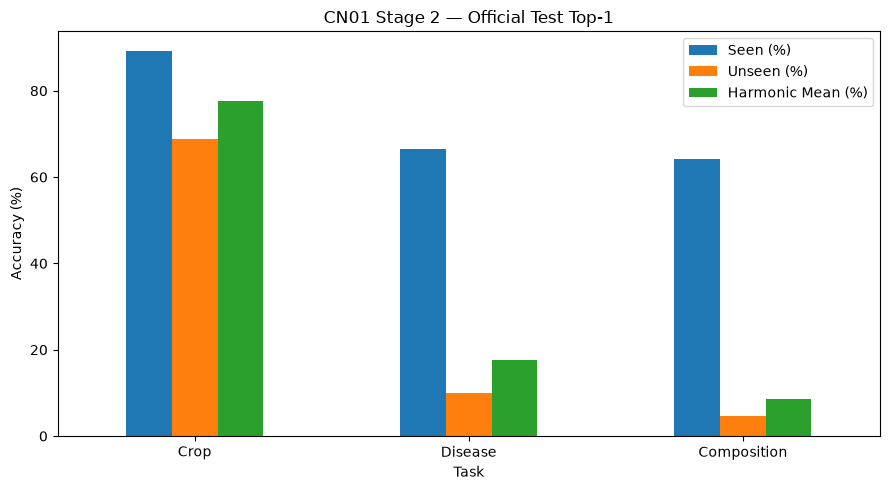

,Task,Top-K,Seen (%),Unseen (%),Harmonic Mean (%)
0,Crop,1,89.30,68.78,77.71
1,Crop,5,96.05,84.32,89.81
2,Disease,1,66.40,10.08,17.51
3,Disease,5,88.85,27.97,42.55
4,Composition,1,64.10,4.63,8.63
5,Composition,5,83.60,16.02,26.89


OFFICIAL TEST COMPLETE. No further tuning or alternative test runs.
Results: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01_official_test


In [5]:
RUN_OFFICIAL_TEST = True  # Set True only once after Sections 1–4 pass.
if RUN_OFFICIAL_TEST:
    official_table = run_official_test()
else:
    print('Official Test disabled. No Official Test metadata or images were read by this cell.')

## 6. Results and visualisation

These tables and figures are created from **saved real outputs**. The evaluation itself is not repeated here. Save the notebook after executing so the lecturer can view the tables and figures on GitHub. Results are shown as percentages; the raw metrics JSON stores accuracy as fractions in `[0,1]`.

,Task,Top-K,Seen (%),Unseen (%),Harmonic Mean (%)
0,Crop,1,89.30,68.78,77.71
1,Crop,5,96.05,84.32,89.81
2,Disease,1,66.40,10.08,17.51
3,Disease,5,88.85,27.97,42.55
4,Composition,1,64.10,4.63,8.63
5,Composition,5,83.60,16.02,26.89


official_comparison_top1.png


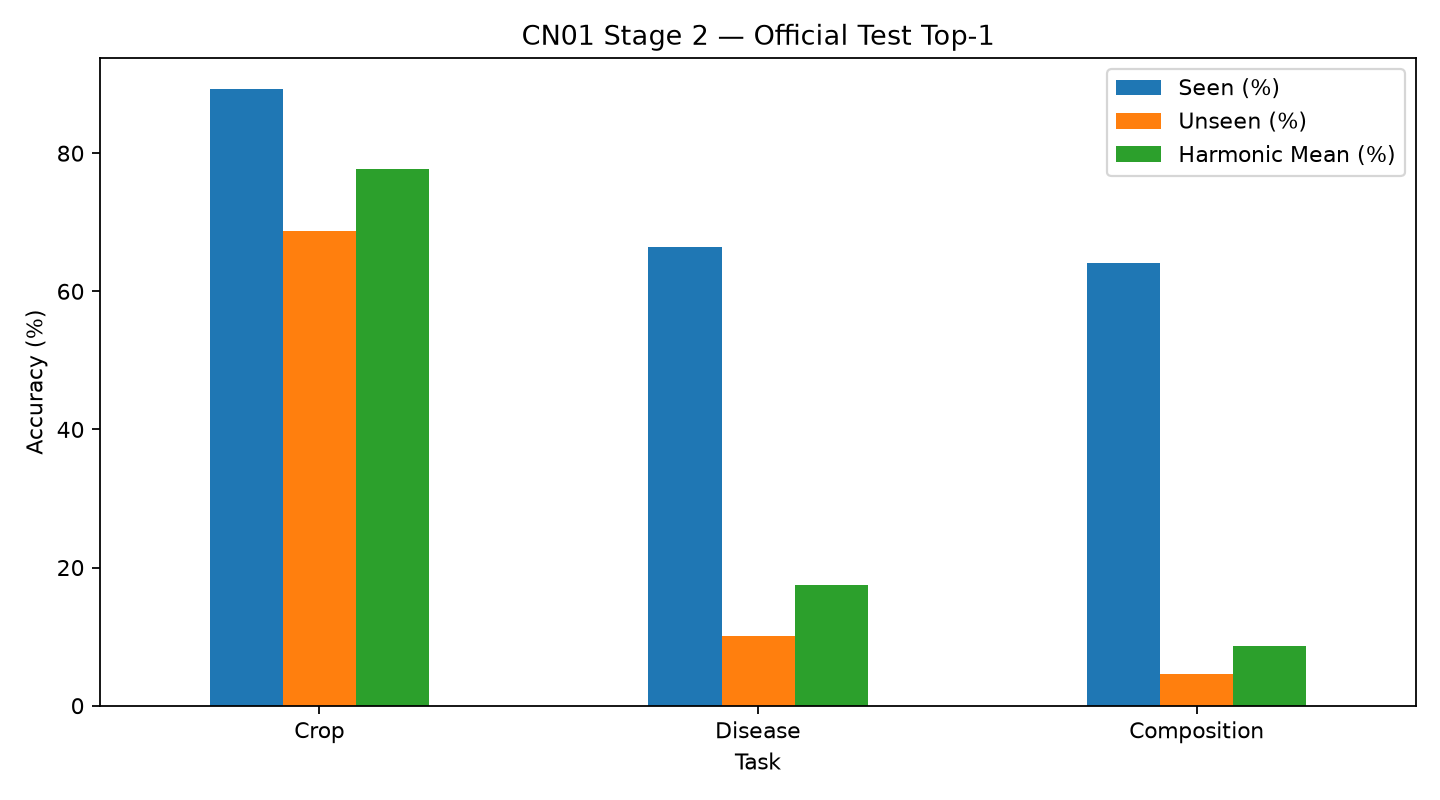

official_seen_confusion.png


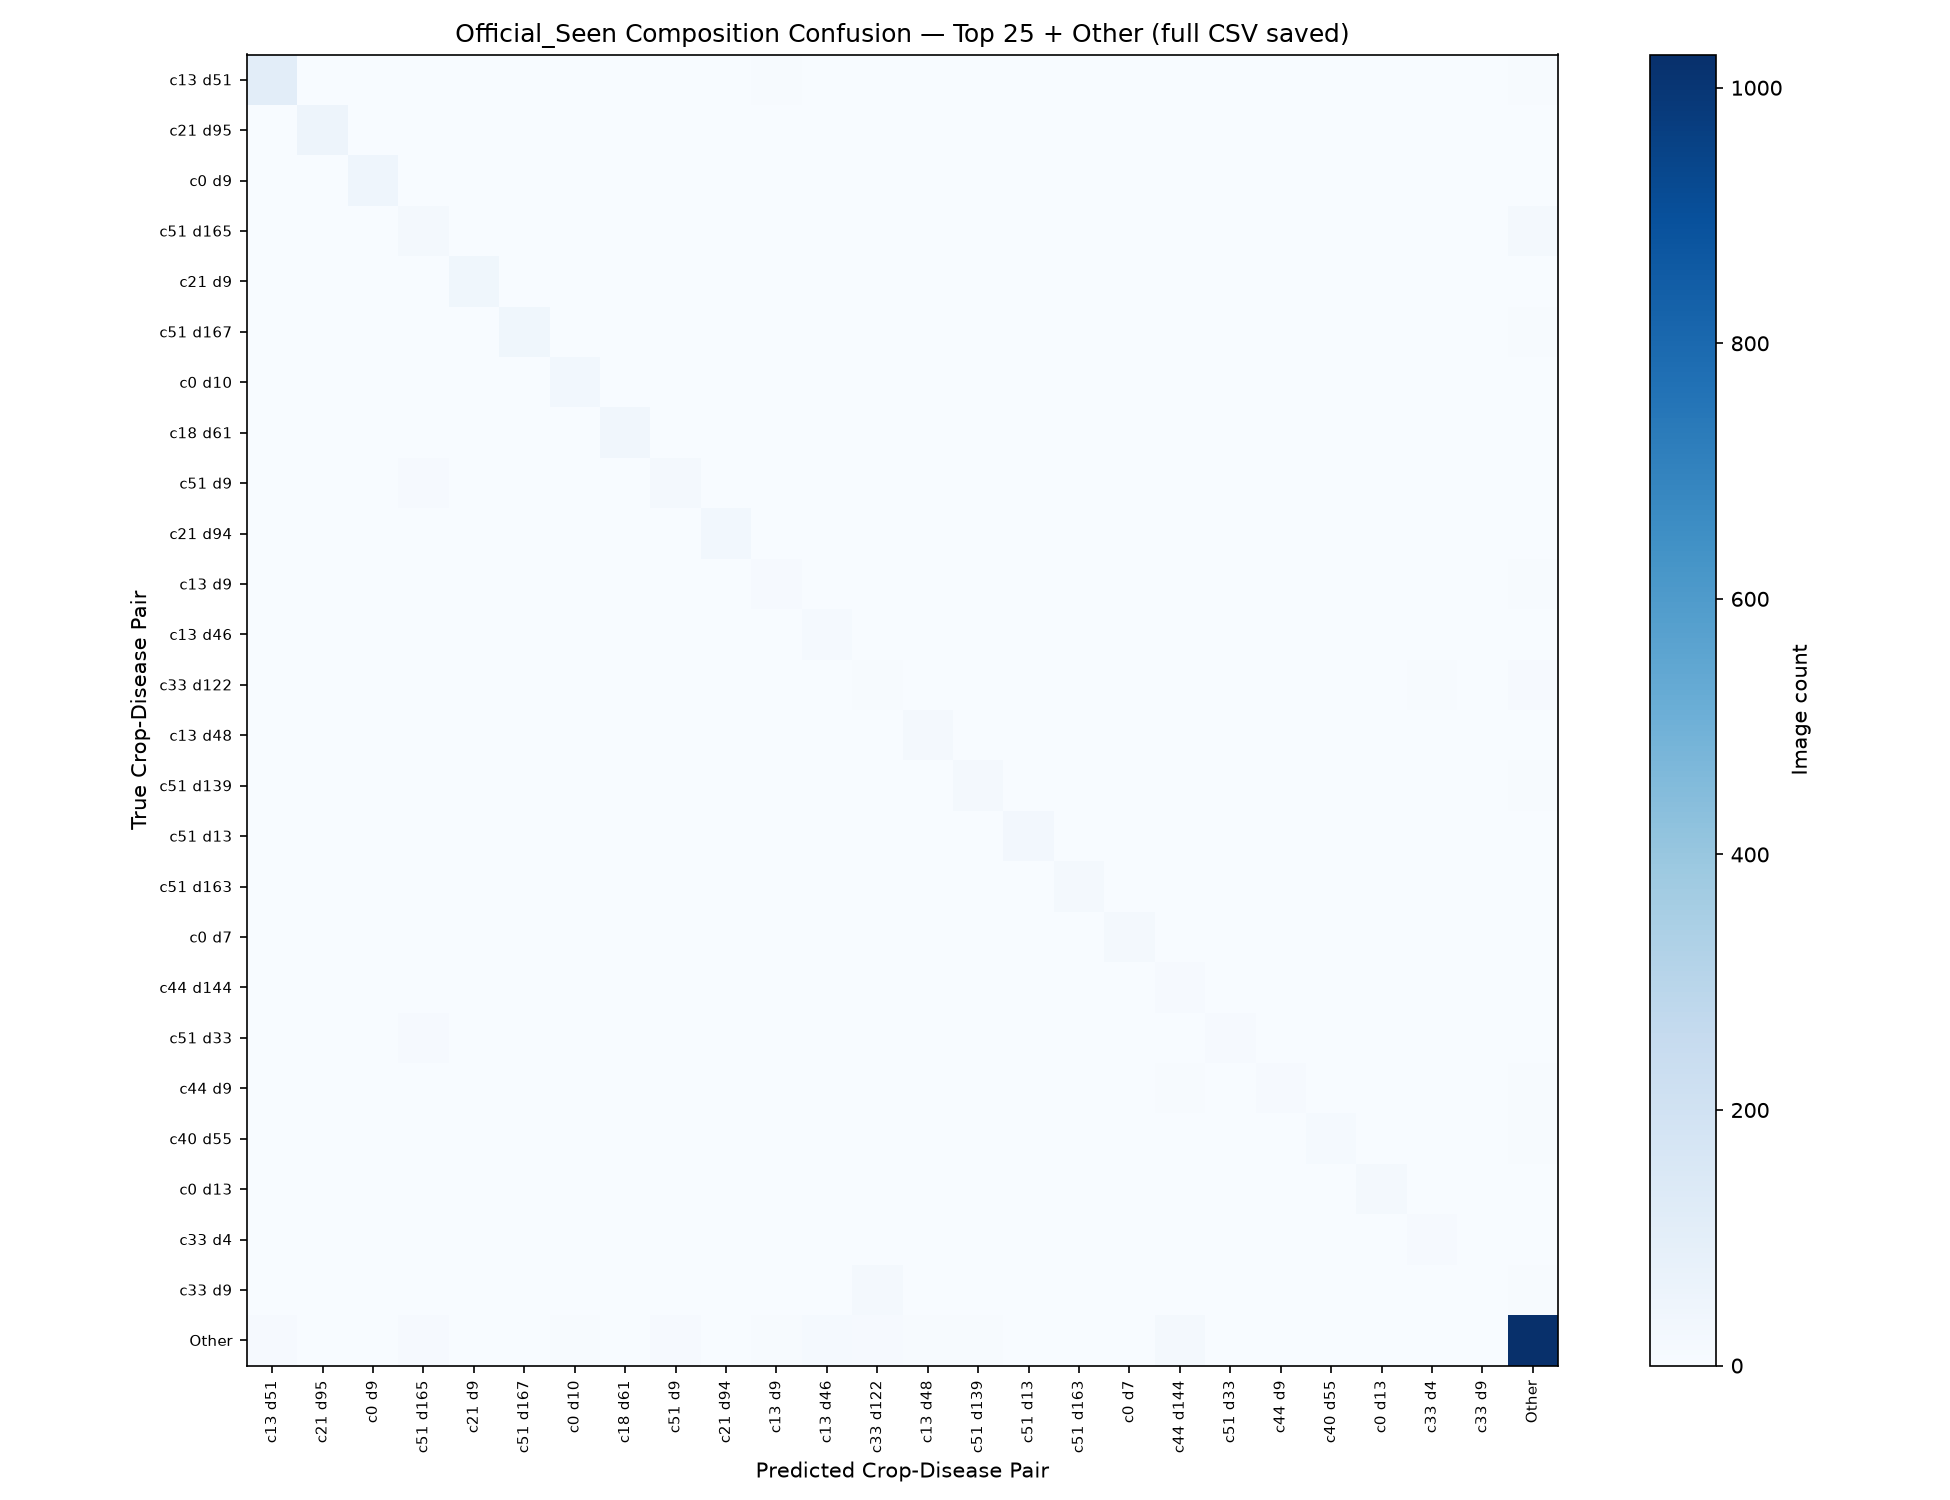

,Split,Predicts train-seen pair (%),Images
0,seen,91.95,2000
1,unseen,67.82,1448


In [6]:
result_file = OFFICIAL_DIR/'official_results_percent.csv'
if result_file.is_file():
    result_table = pd.read_csv(result_file)
    display(result_table.round(2))
    for filename in ('official_comparison_top1.png',
                     'official_seen_crop_confusion_top15.png',
                     'official_seen_disease_confusion_top15.png',
                     'official_seen_confusion.png'):
        img = OFFICIAL_DIR/filename
        if img.is_file():
            print(filename)
            display(IPImage(filename=str(img),width=650))
    bias_file = OFFICIAL_DIR/'seen_pair_prediction_bias.json'
    if bias_file.is_file():
        bias=json.loads(bias_file.read_text(encoding='utf8'))
        display(pd.DataFrame([
            {'Split':k,'Predicts train-seen pair (%)':100*v['prediction_fraction'],
             'Images':v['n_images']} for k,v in bias.items()
        ]).round(2))
else:
    print('No Official Test results yet. No scores or figures are invented.')

### Example predictions and errors

The following gallery takes the **first six misclassified seen-test images** in saved evaluation order. It is illustrative only; the full CSV and aggregate metrics are the evidence. We do not pick cases to make the model look better. This cell runs only after the official results exist.

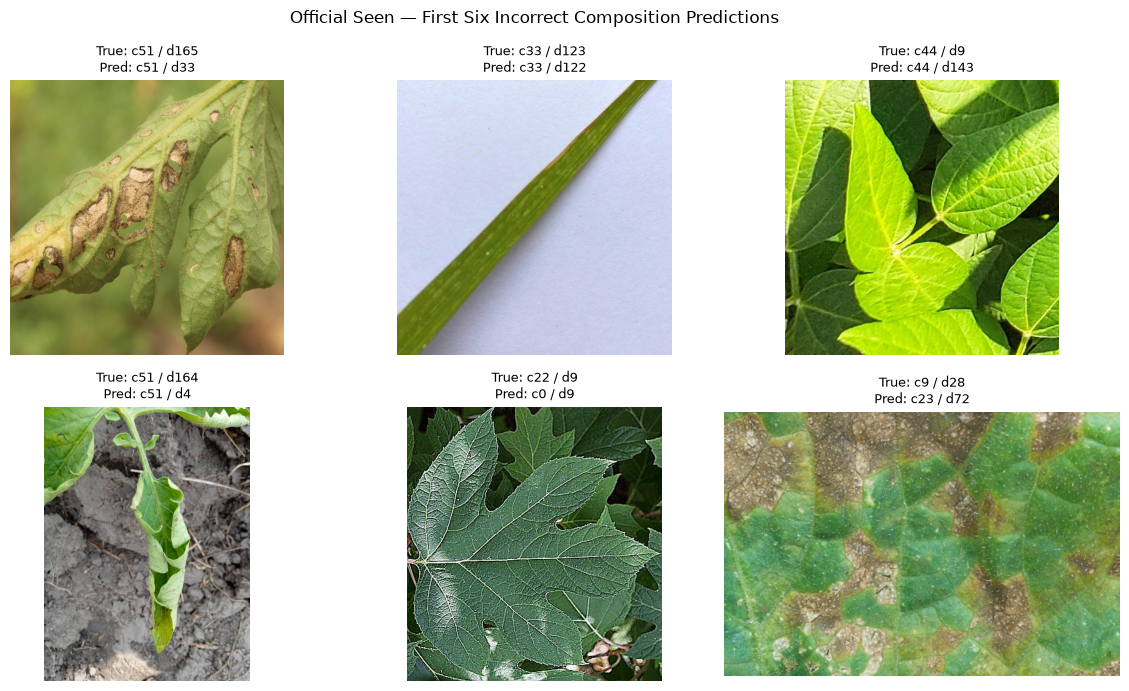

In [7]:
prediction_csv = OFFICIAL_DIR/'official_seen_predictions.csv'
if prediction_csv.is_file():
    preds = pd.read_csv(prediction_csv)
    mistakes = preds[(preds.crop_id != preds.predicted_pair_crop_id) |
                     (preds.disease_id != preds.predicted_pair_disease_id)].head(6)
    if len(mistakes):
        crop_names=checkpoint.get('class_mappings',{}).get('crop',{})
        disease_names=checkpoint.get('class_mappings',{}).get('disease',{})
        fig, axes = plt.subplots(2,3,figsize=(12,7))
        for ax,(_,r) in zip(axes.flat,mistakes.iterrows()):
            image_path = Path(OFFICIAL_IMAGE_ROOT)/str(r.filename).replace('\\','/')
            with Image.open(image_path) as im:
                ax.imshow(im.convert('RGB'))
            t=f"c{int(r.crop_id)} / d{int(r.disease_id)}"
            p=f"c{int(r.predicted_pair_crop_id)} / d{int(r.predicted_pair_disease_id)}"
            ax.set_title(f'True: {t}\nPred: {p}',fontsize=9)
            ax.axis('off')
        for ax in axes.flat[len(mistakes):]:
            ax.axis('off')
        fig.suptitle('Official Seen — First Six Incorrect Composition Predictions',fontsize=12)
        fig.tight_layout()
        fig.savefig(OFFICIAL_DIR/'official_seen_error_examples.png',dpi=140)
        plt.show()
    else:
        print('No misclassified seen examples in saved predictions.')
else:
    print('Saved official predictions are not available yet.')

## 7. Discussion and limitations

**Evaluation.** The same shared-backbone B2 model predicts a 55-class Crop distribution and a 175-class Disease distribution. Each of 9,625 candidate pairs is scored using the sum of corresponding log probabilities. The correct composition requires **both concepts** to match.

**Required reporting.** In the report, present Official Seen and Unseen Top-1/Top-5 for Crop, Disease and Composition, along with each Harmonic Mean. Use the seen-test crop/disease/composition confusion matrices and inspect the most frequent mistakes. Discuss whether unseen errors are primarily crop errors, disease errors or both, and whether predictions favor training-seen pairs.

**Limitations.** The Official Test was performed on a final model defined before observing test outcomes; it must not be used to retune or select competing checkpoints. B1 and B2 differ in task architecture and potentially checkpoint-selection strategy and optimizer grouping; therefore any performance difference may not be caused by architecture alone. Test-versus-development changes reflect different datasets, not proof that Stage 2 helped or harmed.

**GitHub evidence.** Keep this notebook's actual executed outputs. Commit the two `.ipynb` files, shared `.py` modules and small summary PNG/CSV/JSON files as permitted by your group. Avoid committing training/test images, large model weights (`.pt`), `.venv`, or private/unlicensed datasets. If no Official Test has run, leave results empty rather than manufacturing values.